# RQ1 Analytics Prototype

## Research Question

RQ1 investigates whether weather conditions influence social media sentiment across major Australian cities.

The analysis focuses on identifying relationships between:

- temperature
- rainfall
- extreme weather conditions
- sentiment polarity
- posting activity

across Mastodon and BlueSky datasets.

This notebook uses real data retrieved from Elasticsearch, including:

- Mastodon posts
- BlueSky posts
- weather observations

for Melbourne, Sydney, Brisbane, and Perth.

## 1. Environment Setup

This section imports the required Python libraries and establishes a connection to Elasticsearch.

The notebook retrieves real social media and weather data directly from the Elasticsearch cluster.

In [1]:
# ============================================================
# Environment Setup
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from elasticsearch import Elasticsearch

print("Environment setup successful!")

Environment setup successful!


## 2. Connect to Elasticsearch

This section connects the notebook to the Elasticsearch cluster through the local port-forward.

The connection allows direct access to:

- Mastodon posts
- BlueSky posts
- weather datasets

In [2]:
# ============================================================
# Connect to Elasticsearch
# ============================================================

es = Elasticsearch(
    "https://localhost:9200",
    basic_auth=("elastic", "elastic"),
    verify_certs=False,
    request_timeout=60,
)

assert es.ping(), (
    "Cannot connect to Elasticsearch.\n"
    "Make sure port-forward is running."
)

print(f"Connected to Elasticsearch {es.info()['version']['number']}")


Connected to Elasticsearch 9.2.4


## 3. Load Real Data from Elasticsearch

This section retrieves:

- Mastodon posts
- BlueSky posts
- weather observations

from Elasticsearch.

Only posts from the four target cities are included:

- Melbourne
- Sydney
- Brisbane
- Perth

In [3]:
# ============================================================
# Constants
# ============================================================

CITIES = ["Melbourne", "Sydney", "Brisbane", "Perth"]

# Exclude weather-search harvested BlueSky posts
CLEAN_BLUESKY_FILTER = {
    "bool": {
        "must_not": [
            {"wildcard": {"harvest_strategy": "*weather*"}},
            {"term": {"harvest_strategy": "search:heatwave"}},
            {"term": {"harvest_strategy": "search:polar blast"}},
            {"term": {"harvest_strategy": "search:auswx"}},
        ]
    }
}


# ============================================================
# Helper Function: Fetch Posts
# ============================================================

def fetch_posts(index, platform_name,
                cities_only=True,
                query=None,
                batch_size=5000):

    must_clauses = []

    if cities_only:
        must_clauses.append({
            "terms": {
                "city": CITIES
            }
        })

    if query:
        body_query = {
            "bool": {
                "must": must_clauses
            }
        }

        if "bool" in query and "must_not" in query["bool"]:
            body_query["bool"]["must_not"] = query["bool"]["must_not"]

    else:
        body_query = {
            "bool": {
                "must": must_clauses
            }
        }

    pit = es.open_point_in_time(
        index=index,
        keep_alive="2m"
    )["id"]

    records = []

    search_after = None

    source_fields = [
        "city",
        "date",
        "created_at",
        "sentiment_compound",
        "sentiment_label",
        "author_handle",
        "author_acct",
        "content_clean",
    ]

    try:

        while True:

            body = {
                "size": batch_size,
                "query": body_query,
                "sort": [{"_doc": "asc"}],
                "_source": source_fields,
                "pit": {
                    "id": pit,
                    "keep_alive": "2m"
                },
            }

            if search_after:
                body["search_after"] = search_after

            r = es.search(body=body)

            hits = r["hits"]["hits"]

            if not hits:
                break

            for h in hits:

                src = h["_source"]

                records.append({
                    "id": h["_id"],
                    "platform": platform_name,
                    "city": src.get("city"),
                    "date": src.get("date"),
                    "created_at": src.get("created_at"),
                    "sentiment_compound": src.get("sentiment_compound"),
                    "sentiment_label": src.get("sentiment_label"),
                    "author": src.get("author_handle") or src.get("author_acct"),
                    "text": src.get("content_clean"),
                })

            search_after = hits[-1]["sort"]

            if len(hits) < batch_size:
                break

    finally:
        es.close_point_in_time(id=pit)

    df = pd.DataFrame(records)

    if not df.empty:
        df["date"] = pd.to_datetime(df["date"])

    return df


# ============================================================
# Helper Function: Fetch Weather
# ============================================================

def fetch_weather(cities_only=True):

    query = {
        "terms": {
            "city": CITIES
        }
    } if cities_only else {
        "match_all": {}
    }

    pit = es.open_point_in_time(
        index="weather",
        keep_alive="2m"
    )["id"]

    records = []

    search_after = None

    try:

        while True:

            body = {
                "size": 1000,
                "query": query,
                "sort": [{"date": "asc"}],
                "pit": {
                    "id": pit,
                    "keep_alive": "2m"
                },
            }

            if search_after:
                body["search_after"] = search_after

            r = es.search(body=body)

            hits = r["hits"]["hits"]

            if not hits:
                break

            for h in hits:
                records.append(h["_source"])

            search_after = hits[-1]["sort"]

            if len(hits) < 1000:
                break

    finally:
        es.close_point_in_time(id=pit)

    df = pd.DataFrame(records)

    if not df.empty:
        df["date"] = pd.to_datetime(df["date"])

    return df


# ============================================================
# Load Mastodon Posts
# ============================================================

print("Loading Mastodon posts...")

mastodon_df = fetch_posts(
    "posts_mastodon",
    "Mastodon",
    cities_only=True
)

print(f"Loaded {len(mastodon_df):,} Mastodon posts")


# ============================================================
# Load BlueSky Posts
# ============================================================

print("\nLoading BlueSky posts...")

bluesky_df = fetch_posts(
    "posts_bluesky",
    "BlueSky",
    cities_only=True,
    query=CLEAN_BLUESKY_FILTER
)

print(f"Loaded {len(bluesky_df):,} BlueSky posts")


# ============================================================
# Load Weather Data
# ============================================================

print("\nLoading weather data...")

weather_df = fetch_weather(cities_only=True)

print(f"Loaded {len(weather_df):,} weather records")

Loading Mastodon posts...
Loaded 3,817 Mastodon posts

Loading BlueSky posts...
Loaded 6,612 BlueSky posts

Loading weather data...
Loaded 1,492 weather records


## 4. Data Cleaning and Schema Alignment

This section combines Mastodon and BlueSky posts into a single DataFrame.

Field names are standardised to match the prototype workflow.

Timestamp values are converted into a unified UTC datetime format to ensure consistency across platforms.

In [4]:
# ============================================================
# Combine Posts Data
# ============================================================

posts_df = pd.concat(
    [mastodon_df, bluesky_df],
    ignore_index=True
)

print(f"Combined posts: {len(posts_df):,}")

print("\nPosts per platform:")

print(posts_df['platform'].value_counts())


# ============================================================
# Schema Alignment
# ============================================================

df = posts_df.copy()

# Rename ES fields to prototype field names
df = df.rename(columns={
    'created_at': 'timestamp',
    'sentiment_compound': 'sentiment_score'
})


# ============================================================
# Timestamp Cleaning
# ============================================================

df['timestamp'] = pd.to_datetime(
    df['timestamp'],
    utc=True,
    errors='coerce'
)

# Remove invalid timestamps
df = df.dropna(subset=['timestamp'])

# Extract date
df['date'] = df['timestamp'].dt.date


print("\nCleaned DataFrame:")

print(df.head())

Combined posts: 10,429

Posts per platform:
platform
BlueSky     6612
Mastodon    3817
Name: count, dtype: int64

Cleaned DataFrame:
                            id  platform       city        date  \
0  mastodon_116508750314967224  Mastodon  Melbourne  2026-05-03   
1  mastodon_116508013656397792  Mastodon     Sydney  2026-05-03   
2  mastodon_116507797394348902  Mastodon     Sydney  2026-05-03   
3  mastodon_116507699383484378  Mastodon  Melbourne  2026-05-03   
4  mastodon_116504797202356932  Mastodon  Melbourne  2026-05-02   

                         timestamp  sentiment_score sentiment_label  \
0 2026-05-03 04:27:24.992000+00:00           0.7351        positive   
1 2026-05-03 01:20:04.477000+00:00           0.0000         neutral   
2 2026-05-03 00:25:04.584000+00:00           0.0000         neutral   
3 2026-05-03 00:00:09.055000+00:00           0.0000         neutral   
4 2026-05-02 11:42:05.291000+00:00          -0.1820        negative   

            author                   

## 5. Weather Data Integration

This section merges weather observations with social media posts using:

- city
- date

This allows weather conditions to be analysed alongside sentiment scores.

In [6]:
# ============================================================
# Merge Weather Data
# ============================================================

# Ensure matching date formats

df['date'] = pd.to_datetime(df['date'])

weather_df['date'] = pd.to_datetime(weather_df['date'])


# Merge weather data

df = df.merge(
    weather_df,
    on=['city', 'date'],
    how='left'
)

print("Merged DataFrame:")

print(df.head())


print("\nColumns:")

print(df.columns.tolist())

Merged DataFrame:
                          id_x  platform       city       date  \
0  mastodon_116508750314967224  Mastodon  Melbourne 2026-05-03   
1  mastodon_116508013656397792  Mastodon     Sydney 2026-05-03   
2  mastodon_116507797394348902  Mastodon     Sydney 2026-05-03   
3  mastodon_116507699383484378  Mastodon  Melbourne 2026-05-03   
4  mastodon_116504797202356932  Mastodon  Melbourne 2026-05-02   

                         timestamp  sentiment_score sentiment_label  \
0 2026-05-03 04:27:24.992000+00:00           0.7351        positive   
1 2026-05-03 01:20:04.477000+00:00           0.0000         neutral   
2 2026-05-03 00:25:04.584000+00:00           0.0000         neutral   
3 2026-05-03 00:00:09.055000+00:00           0.0000         neutral   
4 2026-05-02 11:42:05.291000+00:00          -0.1820        negative   

            author                                               text id_y  \
0    SaraIsSkyBlue  I think ABC News just said Melbourne City wome...  NaN   
1 

## 6. Cross-Platform Sentiment Comparison

This section compares average sentiment scores between Mastodon and BlueSky.

The analysis helps identify whether different platforms exhibit different sentiment patterns.

platform
BlueSky     0.155766
Mastodon    0.103198
Name: sentiment_score, dtype: float64


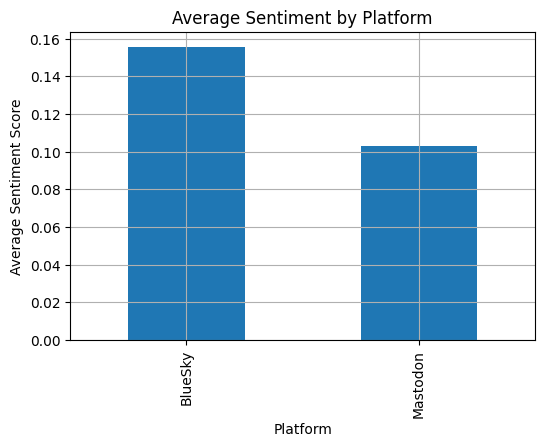

In [7]:
# ============================================================
# Cross-Platform Sentiment Comparison
# ============================================================

platform_sentiment = df.groupby(
    'platform'
)['sentiment_score'].mean()

print(platform_sentiment)


# Plot

plt.figure(figsize=(6,4))

platform_sentiment.plot(
    kind='bar'
)

plt.title('Average Sentiment by Platform')

plt.xlabel('Platform')

plt.ylabel('Average Sentiment Score')

plt.grid(True)

plt.show()

## 7. Temperature vs Sentiment Analysis

This section visualises the relationship between temperature and sentiment scores using a scatter plot.

Each point represents one social media post.

The analysis explores whether higher temperatures are associated with stronger positive or negative sentiment.

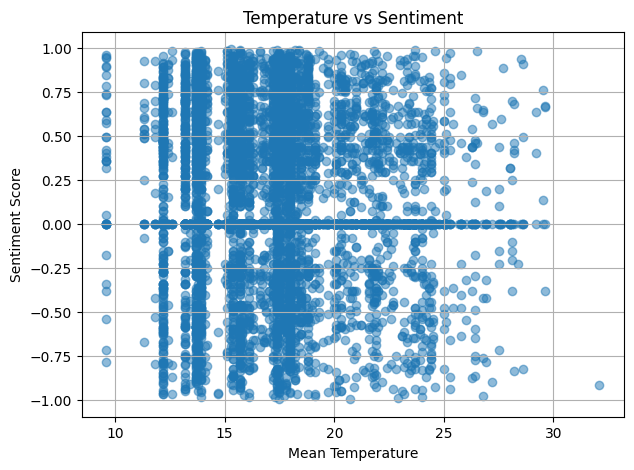

In [9]:
# ============================================================
# Temperature vs Sentiment
# ============================================================

plt.figure(figsize=(7,5))

plt.scatter(
    df['temp_mean'],
    df['sentiment_score'],
    alpha=0.5
)

plt.title('Temperature vs Sentiment')

plt.xlabel('Mean Temperature')

plt.ylabel('Sentiment Score')

plt.grid(True)

plt.show()

## 8. Correlation Analysis

This section calculates the Pearson correlation between temperature and sentiment scores.

The correlation coefficient helps quantify whether temperature and sentiment are linearly related.

In [10]:
# ============================================================
# Correlation Analysis
# ============================================================

correlation = df['temp_mean'].corr(
    df['sentiment_score']
)

print("Temperature vs Sentiment Correlation:")

print(correlation)

Temperature vs Sentiment Correlation:
-0.05661230857982522


## 9. Sentiment Distribution by Platform

This section compares the distribution of positive, neutral, and negative posts across Mastodon and BlueSky.

The visualisation helps identify differences in emotional expression between the two platforms.

sentiment_label  negative  neutral  positive
platform                                    
BlueSky              1084     1583      2216
Mastodon              826     1561      1430


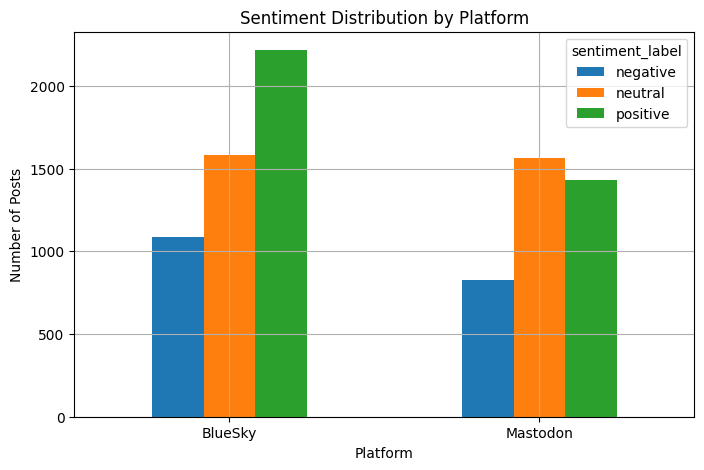

In [11]:
# ============================================================
# Sentiment Distribution by Platform
# ============================================================

sentiment_counts = pd.crosstab(
    df['platform'],
    df['sentiment_label']
)

print(sentiment_counts)

# Plot
sentiment_counts.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Sentiment Distribution by Platform')

plt.xlabel('Platform')

plt.ylabel('Number of Posts')

plt.xticks(rotation=0)

plt.grid(True)

plt.show()

## 10. Posts by City

This section shows the number of social media posts collected from each city.

city
Sydney       3335
Melbourne    2943
Brisbane     1493
Perth         946
Name: count, dtype: int64


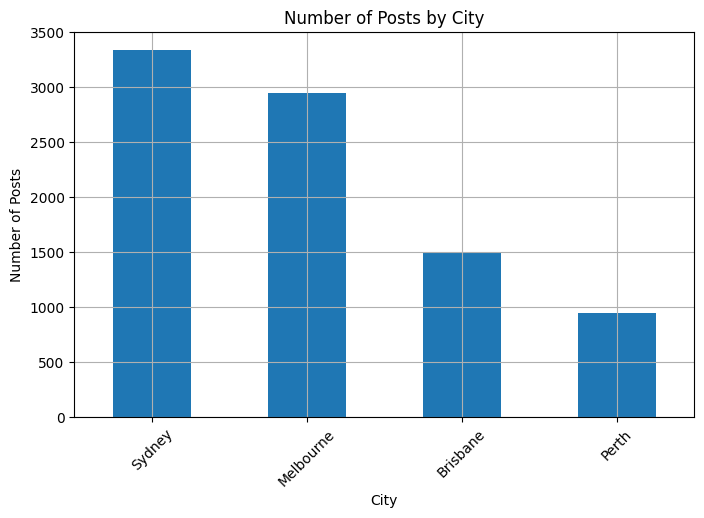

In [12]:
city_counts = df['city'].value_counts()

print(city_counts)

city_counts.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Number of Posts by City')

plt.xlabel('City')

plt.ylabel('Number of Posts')

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

## 11. Sentiment Score Distribution

This section visualises the distribution of sentiment scores across all posts.

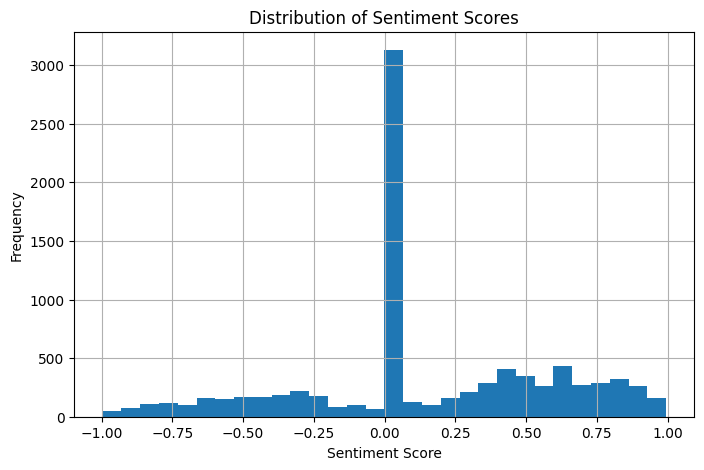

In [14]:
plt.figure(figsize=(8,5))

plt.hist(
    df['sentiment_score'],
    bins=30
)

plt.title('Distribution of Sentiment Scores')

plt.xlabel('Sentiment Score')

plt.ylabel('Frequency')

plt.grid(True)

plt.show()

## 12. Daily Posting Activity

This section examines posting activity over time.

date
2026-01-26    3
2026-01-27    2
2026-01-28    2
2026-01-29    7
2026-01-30    3
dtype: int64


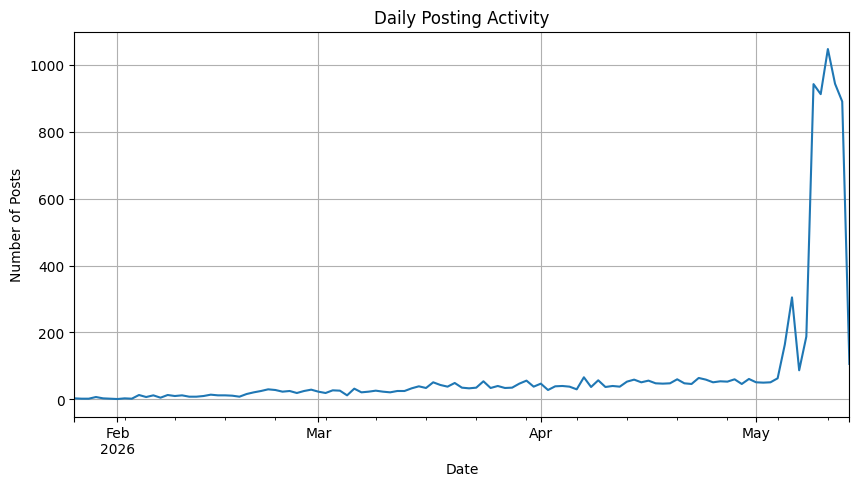

In [15]:
daily_posts = df.groupby('date').size()

print(daily_posts.head())

daily_posts.plot(
    figsize=(10,5)
)

plt.title('Daily Posting Activity')

plt.xlabel('Date')

plt.ylabel('Number of Posts')

plt.grid(True)

plt.show()

## 13. Weather Condition Distribution

This section shows the frequency of different weather conditions in the dataset.

weather_condition
rain             4152
partly_cloudy    3315
clear             728
snow               37
Name: count, dtype: int64


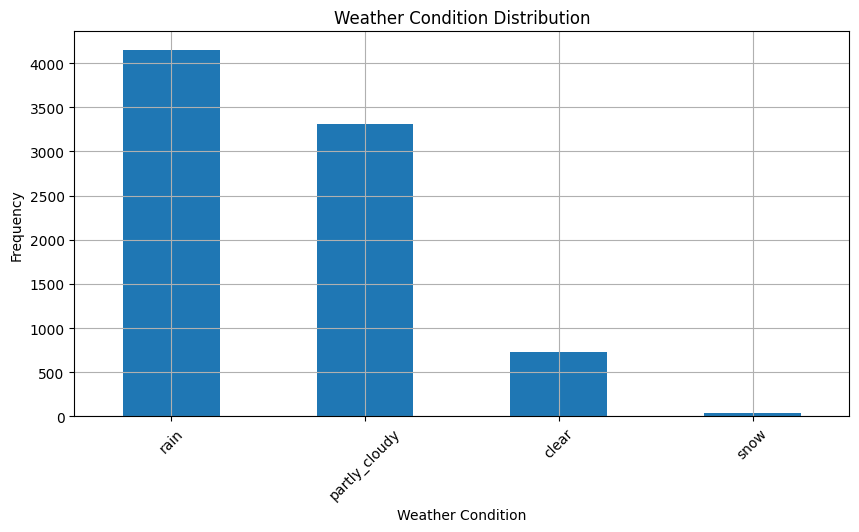

In [16]:
weather_counts = df['weather_condition'].value_counts()

print(weather_counts.head())

weather_counts.plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Weather Condition Distribution')

plt.xlabel('Weather Condition')

plt.ylabel('Frequency')

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

# Preliminary Findings

Several preliminary patterns were identified from the exploratory analysis.

- BlueSky posts generally showed higher average sentiment scores than Mastodon posts.
- Positive sentiment was the dominant category across both platforms.
- Temperature demonstrated only a very weak correlation with sentiment scores.
- Rainy and partly cloudy conditions appeared most frequently in the dataset.
- Posting activity was concentrated mainly in Melbourne and Sydney.
- Different social media platforms appeared to exhibit different emotional expression patterns.

These findings suggest that while weather conditions may influence online activity patterns, their direct impact on sentiment appears relatively limited in this dataset.

# Limitations

Several limitations should be acknowledged in this exploratory analysis.

First, the dataset was limited to four major Australian cities and a relatively short collection period. As a result, the findings may not fully represent broader social media behaviour across Australia.

Second, sentiment scores were generated using automated sentiment analysis techniques. Although useful for large-scale analysis, automated methods may struggle to accurately interpret sarcasm, humour, slang, and context-dependent expressions commonly found in social media posts.

Third, the distribution of weather conditions was uneven. Certain categories, such as snow-related conditions, contained very few observations, which reduced the reliability of comparisons across weather types.

In addition, the observed relationship between temperature and sentiment was relatively weak. This suggests that weather conditions alone may not be sufficient to explain variations in online sentiment, as social media behaviour is also influenced by social, political, cultural, and personal factors.

Finally, preprocessing steps such as timestamp standardisation and missing value handling were required to integrate datasets from multiple platforms. While these steps improved data consistency, minor data loss or transformation bias may still exist.